In [1]:
## load dose script
import glob, os
import numpy as np
import matplotlib.pyplot as pl
import pandas as pd
from datetime import datetime
# !python ./Liheng_scripts/mount_server.py
%run ./Liheng_scripts/Liheng_PB_dose.py
ts = datetime.now().strftime("%Y_%m_%d_%H_%M_%S")
## for office computer, mount the cluster


PB dose calculation loaded, available: please use predict_pencil_beam_dose, distal_falloff_80


In [3]:
# !pip install pandas
# ts = datetime.now().strftime("%Y_%m_%d_%H_%M_%S")
# print(ts)

In [2]:
# path_data = '/mnt/p/data/SynthRAD2023_KD/crop/'
path_data = '/home/liheng/pix2pix/dataset/Syn2023/'

path_CT = path_data+'Image_blocks/'
keyword_i = 'CT'
# ts = datetime.now().strftime("%Y_%m_%d_%H_%M_%S")
print(ts)
save_path = path_data + 'Range/'
if not os.path.isdir(save_path):
    os.makedirs(save_path)

save_file = save_path + keyword_i+ '_'+ts+'.csv'
ene_min = 70.0
ene_max = 220.0
CT_full = glob.glob(path_CT+'*_'+keyword_i+'*')
CT_full[0]

result_this = pd.DataFrame(columns=["name", "energy", "range"])

for CT_file_i in CT_full:
    name_i = os.path.basename(CT_file_i)
    ## need to check if already calculated

    CT_i = np.rint(np.transpose(np.load(CT_file_i), (2, 0, 1))).astype(np.int64)
    if_overshoot = 1
    counter_i = 0
    energy_i = round(np.random.uniform(ene_min, ene_max), 2) ## generate a random energy, penaltrate, reduce
    while if_overshoot == 1:
        # print(energy_i)
        dose_i = predict_pencil_beam_dose(CT_i,energy_mev=energy_i, if_check=0)
        Bragg_i = np.sum(np.sum(dose_i,axis=-1),axis=-1)
        if np.mean(Bragg_i[-5:])<0.1*np.max(Bragg_i): ## no overshooting
            if_overshoot = 0
            break
        else:
            energy_i=np.mean([energy_i,ene_min])
            counter_i = counter_i + 1
        if counter_i >= 10:
            break
    if if_overshoot == 0: ## valid result
        range_i = distal_falloff_80(Bragg_i)
        ## calculate 80% distal fall off
    else:
        range_i = -1
        energy_i = -1
    new_row = pd.DataFrame(
        [[name_i, energy_i, range_i]],
        columns=["name", "energy", "range"]
        )
    result_this = pd.concat([result_this, new_row], ignore_index=True)
    # break # CT blocks
result_this.to_csv(save_file, index=False)

2026_11_10_06_52_00


In [8]:
f_i=0.7

CT_range_file = save_path + 'CT_'+ts+'.csv'

save_file_sCT = save_path + 'sCT_'+str(f_i)+'_'+ts+'.csv'

result_sCT = pd.DataFrame(columns=["name", "energy", "range_p", "range_m"])

CT_info = pd.read_csv(CT_range_file)
key_sCT = 'sCT'
key_un = 'un'
counter_i = 0
for i in range(len(CT_info)):
    name_i = CT_info['name'].iloc[i].split('CT')[0]
    energy_i = CT_info['energy'].iloc[i]
    if energy_i >=70:
        sCT_i = np.transpose(np.load(path_CT+name_i+key_sCT+'.npy'), (2, 0, 1))
        un_i = np.transpose(np.load(path_CT+name_i+key_un+'.npy'), (2, 0, 1))

        sCT_p = np.rint(sCT_i+un_i*f_i).astype(np.int64)
        sCT_m = np.rint(sCT_i-un_i*f_i).astype(np.int64)

        sCT_m[sCT_m<-1000] = -1000 ## we did sCT - f*un here
        # sCT_p[sCT_p<-900] = -1000 ## ???


        dose_p_i = predict_pencil_beam_dose(sCT_p,energy_mev=energy_i, if_check=0)
        dose_m_i = predict_pencil_beam_dose(sCT_m,energy_mev=energy_i, if_check=0)

        Bragg_p_i = np.sum(np.sum(dose_p_i,axis=-1),axis=-1)
        Bragg_m_i = np.sum(np.sum(dose_m_i,axis=-1),axis=-1)

        range_p_i = distal_falloff_80(Bragg_p_i)
        range_m_i = distal_falloff_80(Bragg_m_i)
    else: 
        energy_i = -1
        range_p_i = -1
        range_m_i = -1
    new_row = pd.DataFrame(
            [[name_i, energy_i, range_p_i, range_m_i]],
            columns=["name", "energy", "range_p", "range_m"]
            )
    result_sCT = pd.concat([result_sCT, new_row], ignore_index=True)
    if min(range_m_i, range_p_i) <= CT_info['range'].iloc[i] <= max(range_m_i, range_p_i):
        counter_i = counter_i+1
    # if i % 100 == 0:
    #     print(i)
result_sCT.to_csv(save_file_sCT, index=False)
print('f = ',f_i)
print(counter_i/len(CT_info))
    # break # CT blocks

f =  0.7
0.926


In [7]:
result_CT = pd.read_csv(CT_range_file)
result_sCT = pd.read_csv(save_file_sCT)
counter_i = 0
for i in range(len(CT_info)):
    name_CT_i = result_CT['name'].iloc[i].split('CT')[0]
    name_sCT_i = result_sCT['name'].iloc[i].split('sCT')[0]

    if not name_CT_i == name_sCT_i:
        print('mismatch at ',i)
    else:
        range_CT= result_CT['range'].iloc[i]
        range_m = result_sCT['range_m'].iloc[i]
        range_p = result_sCT['range_p'].iloc[i]
        if min(range_m, range_p) <= range_CT <= max(range_m, range_p):
            counter_i = counter_i+1
        # else:
        #     break
print(counter_i/len(CT_info))
    # break
    # energy_i = CT_info['energy'].iloc[i]

0.8301698301698301


In [12]:
# pl.plot([0.3,0.5,0.7,1],[0.62,0.83,0.91,0.96])

In [7]:
sCT_m.min()

np.int64(-1033)

In [78]:
# def distal_falloff_80(dose,spacing=1,if_check=0):
#     peak_idx = np.argmax(dose)  
#     peak_val = dose[peak_idx]
#     target = 0.8 * peak_val
#     distal = dose[peak_idx + 1 :]
#     below = np.where(distal <= target)[0]
#     if below.size == 0:
#         return np.nan                  # never reaches 80 %
#     # index relative to the whole array (including the peak)
#     idx_right = peak_idx + 1 + below[0]   # the first point *below* target
#     idx_left  = idx_right - 1             # the point just above target
#     y_left, y_right = dose[idx_left], dose[idx_right]
#     # fraction of the interval where the target sits
#     if y_right == y_left:               # avoid division by zero (unlikely)
#         frac = 0.0
#     else:
#         frac = (target - y_left) / (y_right - y_left)

#     # interpolated depth (in sample units)
#     depth_idx = idx_left + frac

#     if if_check==1:
#         pl.plot(dose/dose[peak_idx])
#         pl.plot([depth_idx,depth_idx],[0,1])
#         pl.plot([0,len(dose)],[0.8,0.8],'--')

#     return depth_idx * spacing
#     # print(peak_val)

# distal_falloff_80(Bragg_i,if_check=1)

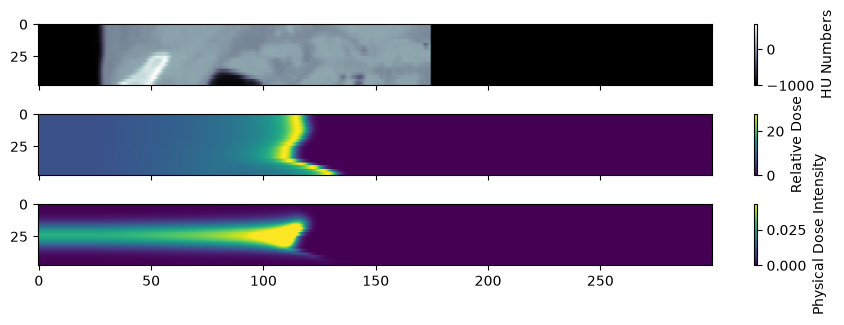

array([[[2.06121593e-08, 3.66272103e-08, 6.35125424e-08, ...,
         1.07470794e-07, 6.35239805e-08, 3.66272103e-08],
        [3.66272103e-08, 6.50854922e-08, 1.12859949e-07, ...,
         1.90972490e-07, 1.12880217e-07, 6.50854922e-08],
        [6.35125424e-08, 1.12859949e-07, 1.95702109e-07, ...,
         3.31151302e-07, 1.95737158e-07, 1.12868116e-07],
        ...,
        [1.07470794e-07, 1.90972490e-07, 3.31151302e-07, ...,
         5.60482759e-07, 3.31231520e-07, 1.90972490e-07],
        [6.35125424e-08, 1.12859949e-07, 1.95702109e-07, ...,
         3.31231520e-07, 1.95749679e-07, 1.12859949e-07],
        [3.66272103e-08, 6.50854922e-08, 1.12859949e-07, ...,
         1.91018918e-07, 1.12887481e-07, 6.50854922e-08]],

       [[2.06121593e-08, 3.66272103e-08, 6.35125424e-08, ...,
         1.07470794e-07, 6.35436728e-08, 3.66272103e-08],
        [3.66272103e-08, 6.50854922e-08, 1.12859949e-07, ...,
         1.90972490e-07, 1.12914906e-07, 6.50854922e-08],
        [6.35125424e-08, 

In [ ]:
# predict_pencil_beam_dose(CT_i,energy_mev=energy_i, if_check=1)

PB dose calculation loaded, please use predict_pencil_beam_dose function


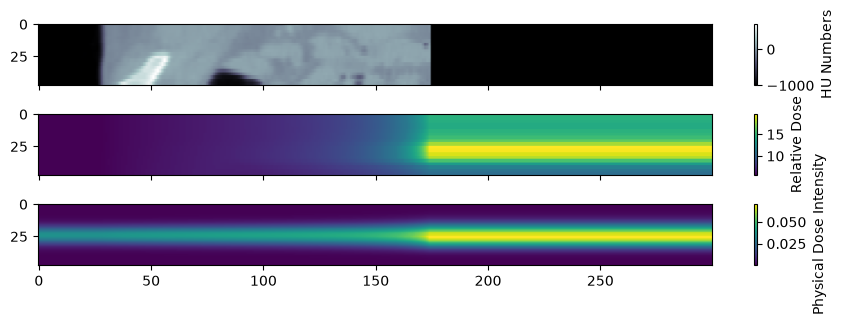

In [ ]:
# %run ./Liheng_scripts/Liheng_PB_dose.py
# CT_i[175:,:,:]=-1000
# dose_i = predict_pencil_beam_dose(CT_i,energy_mev=150.0, if_check=1)

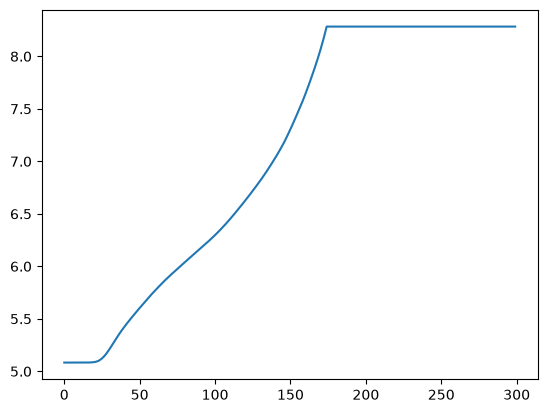

In [64]:
pl.plot(np.sum(np.sum(dose_i,axis=-1),axis=-1))